# Basic map

Basic example of making grid from geojson.


In the following cell, we loop over each pixel in turn starting with the first column and working down. We find the bounds of the pixel and limit the gdf to those bounds. Then if there are any LSOA in the bounds, we calculate the total area occupied by the LSOA (which is not always the full area of the cell if it includes the sea or the Scottish border), and then find the proportion of the land area that is represented by each LSOA. These results are stored in a dictionary and then a DataFrame with the pixels identified by a single value, the column + row number.

## Code setup

In [2]:
import os
from dataclasses import dataclass

import geopandas as gpd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.patches import Rectangle
from matplotlib.patches import Patch  # for legend
import cmasher as cmr  # for extra colourmaps

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.grid
import isopods.stick
import isopods.convert

In [3]:
@dataclass(frozen=True)
class Paths:
    '''Singleton object for storing paths to data and database.'''

    dir_data: str = '../data'
    district_filename: str = 'lsoa2011_devon_districts.geojson'

paths = Paths()

## Load data

Shapes for districts in Devon as formed from LSOA 2011 shapes. Make sure the GeoDataFrame index is the label for each region.

In [4]:
p = os.path.join(paths.dir_data, paths.district_filename)
gdf = gpd.read_file(p).set_index('area_name')
gdf['geometry'] = gdf.make_valid()

In [5]:
gdf.head(3)

,geometry
area_name,
East Devon,"POLYGON ((302024.203 79539.101, 301946.196 795..."
Exeter,"POLYGON ((291388.001 89272.594, 291364.999 893..."
Mid Devon,"POLYGON ((278466.094 93477.102, 278165.937 933..."


Check the coordinate reference system (CRS):

In [6]:
gdf.crs

<Projected CRS: EPSG:27700>
Name: OSGB36 / British National Grid
Axis Info [cartesian]:
- E[east]: Easting (metre)
- N[north]: Northing (metre)
Area of Use:
- name: United Kingdom (UK) - offshore to boundary of UKCS within 49°45'N to 61°N and 9°W to 2°E; onshore Great Britain (England, Wales and Scotland). Isle of Man onshore.
- bounds: (-9.01, 49.75, 2.01, 61.01)
Coordinate Operation:
- name: British National Grid
- method: Transverse Mercator
Datum: Ordnance Survey of Great Britain 1936
- Ellipsoid: Airy 1830
- Prime Meridian: Greenwich

## Generate colours for districts

Generate some colours to go with these districts.

In [7]:
place_names = gdf.index.unique()
colours = plt.get_cmap('cmr.rainforest_r')(
    np.linspace(0.1, 0.9, len(place_names)))
dict_place_colours = dict(zip(place_names, colours))

Check that these colours are in either RGB or RGBA tuple format:

In [8]:
dict_place_colours

{'East Devon': array([0.98454982, 0.84081997, 0.69011015, 1.        ]),
 'Exeter': array([0.86245947, 0.75490816, 0.33632669, 1.        ]),
 'Mid Devon': array([0.61615466, 0.71479652, 0.00628442, 1.        ]),
 'North Devon': array([0.30995941, 0.6639361 , 0.27364605, 1.        ]),
 'Plymouth': array([0.1034372 , 0.56728829, 0.42002408, 1.        ]),
 'South Hams': array([0.02133114, 0.45949578, 0.48288771, 1.        ]),
 'Teignbridge': array([0.03431301, 0.34607743, 0.53151696, 1.        ]),
 'Torbay': array([0.19021288, 0.19165743, 0.57745873, 1.        ]),
 'Torridge': array([0.23712033, 0.00397543, 0.41810379, 1.        ]),
 'West Devon': array([0.12909439, 0.0203135 , 0.14402636, 1.        ])}

Place the colours in the dataframe and make some patches for a pyplot legend.

In [9]:
gdf['colour'] = gdf.index.map(dict_place_colours)

In [10]:
legend_elements = [
    Patch(facecolor=colour, edgecolor='k', label=place)
    for place, colour in dict_place_colours.items()
]

## Set up grid

First, find the bounding box to see the spatial extent of the shapes:

In [11]:
bbox_shapes = gdf.total_bounds

bbox_shapes

array([212711.6182,  34957.4029, 337605.812 , 151204.9973])

We should define a grid that aligns nicely with the British National Grid. Instead of starting our grid at the top left corner of this bounding box, we'll start at the nearest sensible round number.

Say we want cells to be 10km across and tall. Then the nearest sensible starting points are:

In [12]:
cell_width = 10000  # metres
cell_height = 10000  # metres

xmin = (bbox_shapes[0] // cell_width) * cell_width
ymin = (bbox_shapes[1] // cell_height) * cell_height
xmax = ((bbox_shapes[2] // cell_width) + 1.0) * cell_width
ymax = ((bbox_shapes[3] // cell_height) + 1.0) * cell_height

bbox_grid = (xmin, ymin, xmax, ymax)

In [13]:
for b, g in zip(bbox_shapes, bbox_grid):
    print(f'{b:8.1f} {g:8.0f}')

212711.6   210000
 34957.4    30000
337605.8   340000
151205.0   160000


The following function does the same calculation:

In [14]:
bbox_grid = isopods.grid.make_grid_bounds_containing_bbox(
    bbox_shapes, cell_width, cell_height)

bbox_grid

[np.float64(210000.0),
 np.float64(30000.0),
 np.float64(340000.0),
 np.float64(160000.0)]

Make the transform dictionary based on these starting points:

In [15]:
# Prepare some variables
transform_dict = isopods.grid.make_transform_dict(
    bbox_grid, cell_width, cell_height)

In [16]:
transform_dict

{'xmin': np.float64(210000.0),
 'ymax': np.float64(160000.0),
 'cell_width': 10000,
 'cell_height': 10000,
 'n_cols': 13,
 'n_rows': 13,
 'xmax': np.float64(340000.0),
 'ymin': np.float64(30000.0)}

The grid will cover this extent:

In [17]:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

The grid starts from the top left of the bounding box and continues down and right in cells until it has made a cell that contains the bottom right of the bounding box.

## View grid setup

Draw the original shapes and the grid:

In [18]:
def plot_grid(ax, td):
    """td is transform_dict"""
    
    ax.xaxis.set_major_locator(ticker.MultipleLocator(2*td['cell_width'],
                                                      offset=td['xmin']))
    ax.xaxis.set_minor_locator(ticker.MultipleLocator(td['cell_width'],
                                                      offset=td['xmin']))
    
    ax.yaxis.set_major_locator(ticker.MultipleLocator(2*td['cell_height'],
                                                      offset=td['ymin']))
    ax.yaxis.set_minor_locator(ticker.MultipleLocator(td['cell_height'],
                                                      offset=td['ymin']))

    ax.grid(which='both')
    
    ax.set_xlim(td['xmin'], td['xmax'])
    ax.set_ylim(td['ymin'], td['ymax'])
    ax.set_aspect('equal')

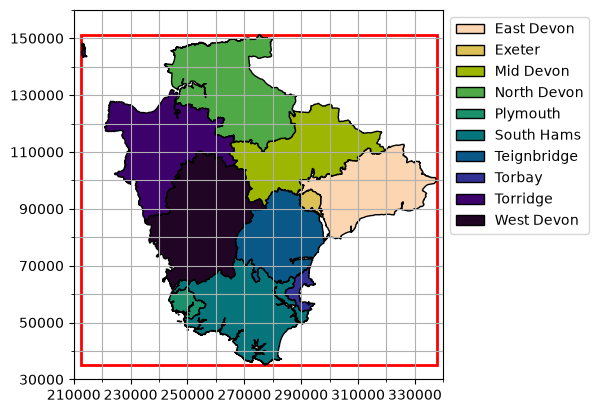

In [19]:
fig, ax = plt.subplots()

# Bounding box of gdf:
gdf_bounds = Rectangle(
    bbox_shapes[:2],  # (x, y) of bottom left corner
    bbox_shapes[2]-bbox_shapes[0],  # width
    bbox_shapes[3]-bbox_shapes[1],  # height
    facecolor='none', edgecolor='r', linewidth=2,
)
ax.add_patch(gdf_bounds)

# Shapes:
gdf.plot(ax=ax, color=gdf['colour'], edgecolor='k')

plot_grid(ax, transform_dict)
ax.legend(handles=legend_elements, bbox_to_anchor=(1.0, 1.0),
          loc='upper left')

plt.show()

## Stick shapes to grid

In [20]:
df_props = isopods.stick.stick_shapes_to_grid(
    gdf, **transform_dict, print_progress=True)

100.0% of cells checked

Check the results for the first few cells that contain any shapes:

In [21]:
df_props.head(3)

,cell_row,cell_col,label_props,area_props,prop_cell_covered,label_majority,overlapping_polys
cell_label,,,,,,,
11,11,0,[Torridge],[1.0],0.042,Torridge,0
19,6,1,[Torridge],[1.0],0.014,Torridge,0
20,7,1,[Torridge],[1.0],0.248,Torridge,0


Pick out some cells containing multiple shapes:

In [22]:
mask = df_props['label_props'].str.len() > 1
df_props[mask].head()

,cell_row,cell_col,label_props,area_props,prop_cell_covered,label_majority,overlapping_polys
cell_label,,,,,,,
31,5,2,"[West Devon, Torridge]","[0.623, 0.377]",0.425,West Devon,0
41,2,3,"[Plymouth, South Hams]","[0.955, 0.045]",0.391,Plymouth,0
42,3,3,"[West Devon, South Hams, Plymouth]","[0.684, 0.202, 0.114]",0.610,West Devon,0
44,5,3,"[West Devon, Torridge]","[0.929, 0.071]",1.000,West Devon,0
45,6,3,"[West Devon, Torridge]","[0.652, 0.348]",1.000,West Devon,0


Did all of the areas make it into the grid?

In [23]:
set(gdf.index) - set(df_props['label_majority'])

{'Exeter'}

Exeter is missing from the grid.

## Convert dataframe to 2D grid

Find the labels of the shape in each cell:

In [24]:
arr_places = isopods.convert.convert_df_to_2darray(
    df_props, 'label_majority', **transform_dict)

In [25]:
arr_places.shape

(13, 13)

In [26]:
arr_places[:2]

masked_array(
  data=[[--, --, --, --, --, 'South Hams', 'South Hams', 'South Hams',
         --, --, --, --, --],
        [--, --, --, 'South Hams', 'South Hams', 'South Hams',
         'South Hams', 'South Hams', 'South Hams', --, --, --, --]],
  mask=[[ True,  True,  True,  True,  True, False, False, False,  True,
          True,  True,  True,  True],
        [ True,  True,  True, False, False, False, False, False, False,
          True,  True,  True,  True]],
  fill_value=np.str_('?'),
  dtype=object)

And finally, convert the place names to their colours:

In [27]:
arr_colours = isopods.convert.convert_grid_values(
    arr_places, dict_place_colours)

In [28]:
arr_colours[:2, 0, :]

masked_array(
  data=[[--, --, --, --],
        [--, --, --, --]],
  mask=[[ True,  True,  True,  True],
        [ True,  True,  True,  True]],
  fill_value=1e+20,
  dtype=float64)

## Plot the grids

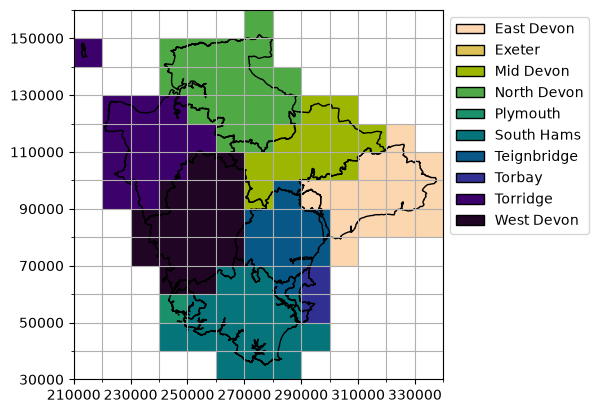

In [29]:
fig, ax = plt.subplots()

# Gridded values:
ax.imshow(arr_colours, origin='lower', extent=extent)

# Shapes:
gdf.plot(ax=ax, facecolor='None', edgecolor='k')

plot_grid(ax, transform_dict)
ax.legend(handles=legend_elements, bbox_to_anchor=(1.0, 1.0),
          loc='upper left')

plt.show()

This grid is too sparse to be of much use. It doesn't line up well with the original shapes, and Exeter is not represented by any grid cell.

## Conclusion

Example of how to convert geojson shapes into a grid.

In the next notebook we'll look at picking the best cell sizes.